<a href="https://colab.research.google.com/github/SUPRAJ29DB/Animal-and-Object-Classification/blob/main/Animal%20and%20Object%20Classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
import numpy as np
import matplotlib.pyplot as plt

In [3]:
import tensorflow as tf

print(tf.config.list_physical_devices("GPU"))

[]


In [1]:

import tensorflow as tf

print("TensorFlow version:", tf.__version__)
print("GPU devices:", tf.config.list_physical_devices("GPU"))

if tf.config.list_physical_devices("GPU"):
    print("GPU detected!")
else:
    print("No GPU detected. Check the runtime settings.")


TensorFlow version: 2.21.0
GPU devices: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
GPU detected!


In [3]:
from tensorflow.keras.datasets import cifar10

In [5]:
import tensorflow as tf
from sklearn.model_selection import train_test_split

(x_train, y_train), (x_test, y_test) = cifar10.load_data()
print("Training images:", x_train.shape)
print("Testing images:", x_test.shape)
print("Dataset downloaded successfully!")

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 2383s 14us/step
Training images: (50000, 32, 32, 3)
Testing images: (10000, 32, 32, 3)
Dataset downloaded successfully!


In [8]:
from tensorflow.keras import layers, models
model=models.Sequential([
    layers.Input(shape=(32,32,3)),
    layers.Conv2D(32, (3,3), activation="relu", padding="same"),
    layers.MaxPooling2D((2,2)),
    layers.Conv2D(64, (3,3), activation="relu", padding="same"),
    layers.MaxPooling2D((2,2)),
    layers.Conv2D(128, (3,3), activation="relu", padding="same"),
    layers.MaxPooling2D((2,2)),
    layers.Flatten(),
    layers.Dense(64, activation="relu"),
    layers.Dense(10, activation="softmax")
])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 8, 8, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │       131,136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 225,034 (879.04 KB)

 Trainable params: 225,034 (879.04 KB)

 Non-trainable params: 0 (0.00 B)

In [9]:
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [10]:
history = model.fit(
    x_train.astype("float32") / 255.0,
    y_train,
    epochs=10,
    batch_size=64,
    validation_split=0.1
)

Epoch 1/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 16s 13ms/step - accuracy: 0.4318 - loss: 1.5602 - val_accuracy: 0.5758 - val_loss: 1.2067
Epoch 2/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.6088 - loss: 1.1150 - val_accuracy: 0.6480 - val_loss: 1.0264
Epoch 3/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.6701 - loss: 0.9443 - val_accuracy: 0.7026 - val_loss: 0.8827
Epoch 4/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.7097 - loss: 0.8321 - val_accuracy: 0.6780 - val_loss: 0.9243
Epoch 5/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.7379 - loss: 0.7570 - val_accuracy: 0.7260 - val_loss: 0.8046
Epoch 6/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.7597 - loss: 0.6946 - val_accuracy: 0.7346 - val_loss: 0.7908
Epoch 7/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.7778 - loss: 0.6410 - val_accuracy: 0.7352 - val_loss: 0.7946
Epoch 8/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.7973 - loss: 0.5869 - val_accuracy: 

In [18]:

history = model.fit(
    x_train.astype("float32") / 255.0,
    y_train,
    epochs=100,
    batch_size=64,
    validation_split=0.1,
    #callbacks=[early_stopping],
    verbose=1
)


Epoch 1/100
704/704 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.8849 - loss: 0.3311 - val_accuracy: 0.7470 - val_loss: 0.9425
Epoch 2/100
704/704 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.8897 - loss: 0.3139 - val_accuracy: 0.7530 - val_loss: 0.8712
Epoch 3/100
704/704 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.8976 - loss: 0.2894 - val_accuracy: 0.7414 - val_loss: 0.9327
Epoch 4/100
704/704 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.9096 - loss: 0.2571 - val_accuracy: 0.7496 - val_loss: 0.9651
Epoch 5/100
704/704 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.9148 - loss: 0.2417 - val_accuracy: 0.7428 - val_loss: 1.0235
Epoch 6/100
704/704 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.9236 - loss: 0.2154 - val_accuracy: 0.7362 - val_loss: 1.1413
Epoch 7/100
704/704 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.9282 - loss: 0.1988 - val_accuracy: 0.7432 - val_loss: 1.1032
Epoch 8/100
704/704 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.9357 - loss: 0.1796 - val_accu

In [19]:
test_loss, test_accuracy = model.evaluate(
    x_test.astype("float32") / 255.0,
    y_test,
    verbose=1
)

print("Test Loss:", test_loss)
print(f"Test Accuracy: {test_accuracy * 100:.2f}%")

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7207 - loss: 3.4423
Test Loss: 3.4423046112060547
Test Accuracy: 72.07%


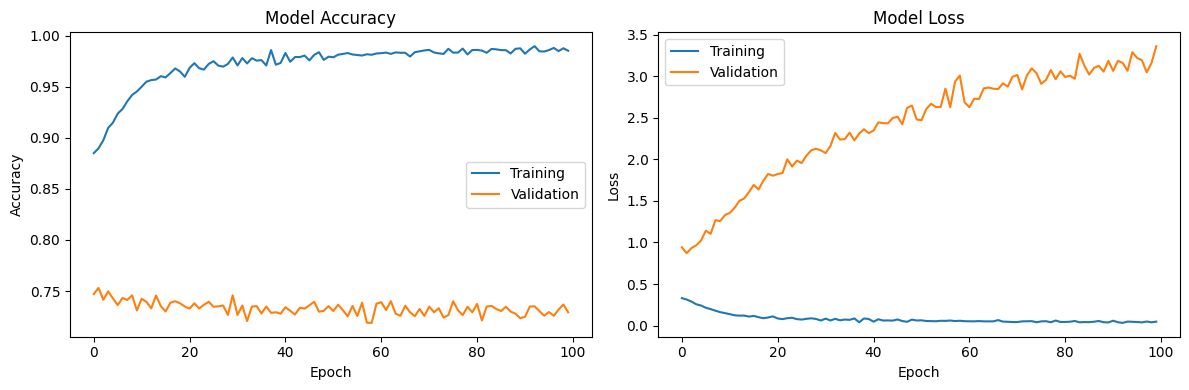

In [20]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training")
plt.plot(history.history["val_accuracy"], label="Validation")
plt.title("Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training")
plt.plot(history.history["val_loss"], label="Validation")
plt.title("Model Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()

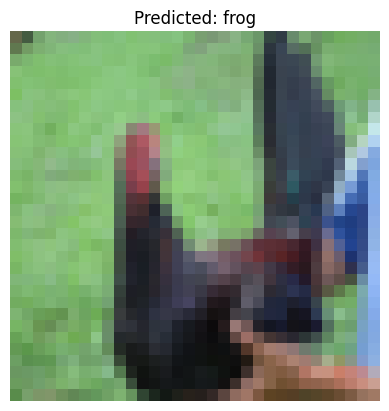

Actual: bird
Predicted: frog
Confidence: 45.76%


In [21]:
import numpy as np
import matplotlib.pyplot as plt

class_names = [
    "airplane", "automobile", "bird", "cat", "deer",
    "dog", "frog", "horse", "ship", "truck"
]

index = 25
image = x_test[index].astype("float32") / 255.0

prediction = model.predict(
    np.expand_dims(image, axis=0),
    verbose=0
)

predicted_class = np.argmax(prediction[0])

plt.imshow(image)
plt.title(f"Predicted: {class_names[predicted_class]}")
plt.axis("off")
plt.show()

print("Actual:", class_names[int(y_test[index].item())])
print("Predicted:", class_names[predicted_class])
print(f"Confidence: {prediction[0][predicted_class] * 100:.2f}%")

In [22]:

import tensorflow as tf
from tensorflow.keras import layers, models

tf.keras.backend.clear_session()

# Data augmentation
data_augmentation = models.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomTranslation(0.1, 0.1),
    layers.RandomRotation(0.05),
], name="data_augmentation")

# Improved CNN
model = models.Sequential([
    layers.Input(shape=(32, 32, 3)),

    layers.Rescaling(1.0 / 255),
    data_augmentation,

    # Block 1
    layers.Conv2D(32, 3, padding="same", use_bias=False),
    layers.BatchNormalization(),
    layers.Activation("relu"),
    layers.Conv2D(32, 3, padding="same", use_bias=False),
    layers.BatchNormalization(),
    layers.Activation("relu"),
    layers.MaxPooling2D(),
    layers.Dropout(0.2),

    # Block 2
    layers.Conv2D(64, 3, padding="same", use_bias=False),
    layers.BatchNormalization(),
    layers.Activation("relu"),
    layers.Conv2D(64, 3, padding="same", use_bias=False),
    layers.BatchNormalization(),
    layers.Activation("relu"),
    layers.MaxPooling2D(),
    layers.Dropout(0.3),

    # Block 3
    layers.Conv2D(128, 3, padding="same", use_bias=False),
    layers.BatchNormalization(),
    layers.Activation("relu"),
    layers.Conv2D(128, 3, padding="same", use_bias=False),
    layers.BatchNormalization(),
    layers.Activation("relu"),
    layers.MaxPooling2D(),
    layers.Dropout(0.3),

    # Classification head
    layers.GlobalAveragePooling2D(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.4),
    layers.Dense(10, activation="softmax")
])

model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 32, 32, 32)     │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 32, 32, 32)     │         9,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 16, 16, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 16, 16, 64)     │        36,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 8, 8, 128)      │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 8, 8, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_4 (Activation)       │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 8, 8, 128)      │       147,456 │
├─────────────────────────────────┼────────────────────────┼─────────────

 Total params: 306,154 (1.17 MB)

 Trainable params: 305,258 (1.16 MB)

 Non-trainable params: 896 (3.50 KB)

In [23]:

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Improved CNN compiled successfully!")


Improved CNN compiled successfully!


In [24]:

callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        "best_cifar10.keras",
        monitor="val_accuracy",
        save_best_only=True,
        mode="max",
        verbose=1
    ),

    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=4,
        min_lr=1e-6,
        verbose=1
    ),

    tf.keras.callbacks.EarlyStopping(
        monitor="val_accuracy",
        patience=12,
        mode="max",
        restore_best_weights=True,
        verbose=1
    )
]

history = model.fit(
    x_train,
    y_train,
    epochs=100,
    batch_size=64,
    validation_split=0.1,
    callbacks=callbacks,
    verbose=1
)


Epoch 1/100
704/704 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - accuracy: 0.3193 - loss: 1.8382
Epoch 1: val_accuracy improved from None to 0.41020, saving model to best_cifar10.keras

Epoch 1: finished saving model to best_cifar10.keras
704/704 ━━━━━━━━━━━━━━━━━━━━ 23s 21ms/step - accuracy: 0.3957 - loss: 1.6389 - val_accuracy: 0.4102 - val_loss: 1.7747 - learning_rate: 0.0010
Epoch 2/100
703/704 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - accuracy: 0.5109 - loss: 1.3434
Epoch 2: val_accuracy improved from 0.41020 to 0.53020, saving model to best_cifar10.keras

Epoch 2: finished saving model to best_cifar10.keras
704/704 ━━━━━━━━━━━━━━━━━━━━ 14s 20ms/step - accuracy: 0.5320 - loss: 1.3010 - val_accuracy: 0.5302 - val_loss: 1.4214 - learning_rate: 0.0010
Epoch 3/100
701/704 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.5716 - loss: 1.1958
Epoch 3: val_accuracy improved from 0.53020 to 0.58940, saving model to best_cifar10.keras

Epoch 3: finished saving model to best_cifar10.keras
704/704 ━━━━━━━━━━

In [25]:

test_loss, test_accuracy = model.evaluate(
    x_test,
    y_test,
    batch_size=64,
    verbose=1
)

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy * 100:.2f}%")


157/157 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.8277 - loss: 0.5156
Test Loss: 0.5156
Test Accuracy: 82.77%


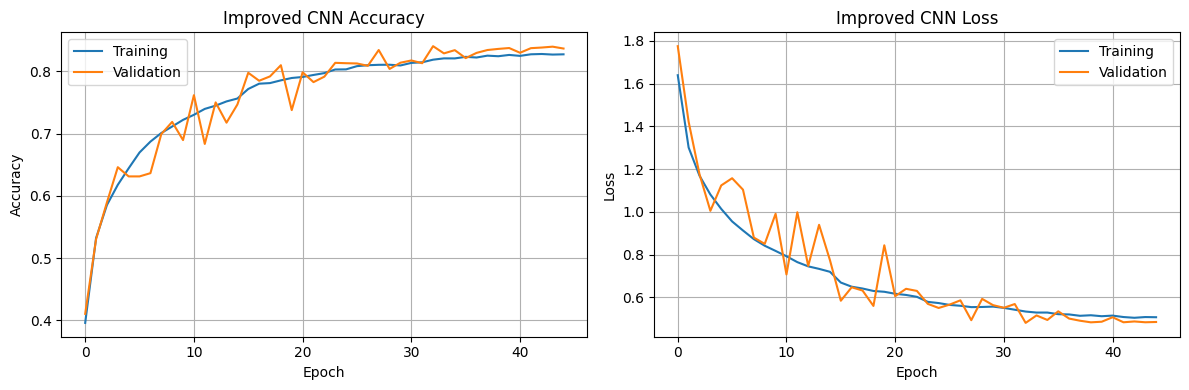

In [26]:

import matplotlib.pyplot as plt

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training")
plt.plot(history.history["val_accuracy"], label="Validation")
plt.title("Improved CNN Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training")
plt.plot(history.history["val_loss"], label="Validation")
plt.title("Improved CNN Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()


In [27]:
model.save("cifar10_cnn_82.keras")

from google.colab import files
files.download("cifar10_cnn_82.keras")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

157/157 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step


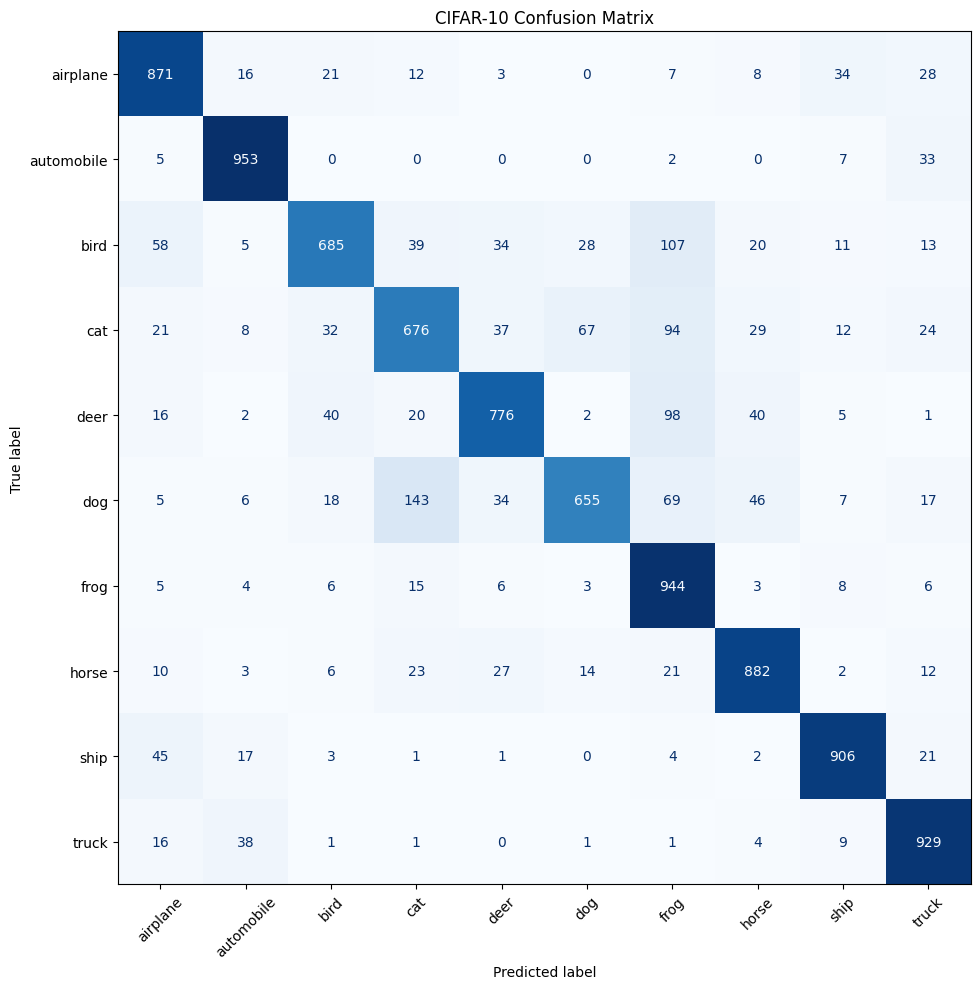

In [28]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

class_names = [
    "airplane", "automobile", "bird", "cat", "deer",
    "dog", "frog", "horse", "ship", "truck"
]

y_pred = np.argmax(model.predict(x_test, batch_size=64), axis=1)

cm = confusion_matrix(y_test.reshape(-1), y_pred)

fig, ax = plt.subplots(figsize=(10, 10))
ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
).plot(ax=ax, xticks_rotation=45, cmap="Blues", colorbar=False)

plt.title("CIFAR-10 Confusion Matrix")
plt.tight_layout()
plt.show()

In [29]:
import numpy as np
import tensorflow as tf
from tensorflow.keras.utils import to_categorical

# Normalize images
x_train_norm = x_train.astype("float32") / 255.0
x_test_norm = x_test.astype("float32") / 255.0

# Convert labels to one-hot format
y_train_onehot = to_categorical(y_train.reshape(-1), 10)

print("Training data:", x_train_norm.shape)
print("Training labels:", y_train_onehot.shape)

Training data: (50000, 32, 32, 3)
Training labels: (50000, 10)


In [30]:
def mixup_batch(images, labels, alpha=0.2):
    batch_size = tf.shape(images)[0]

    lam = tf.random.gamma([], alpha, dtype=tf.float32)
    lam2 = tf.random.gamma([], alpha, dtype=tf.float32)
    lam = lam / (lam + lam2)

    indices = tf.random.shuffle(tf.range(batch_size))

    mixed_images = (
        lam * images +
        (1.0 - lam) * tf.gather(images, indices)
    )

    mixed_labels = (
        lam * labels +
        (1.0 - lam) * tf.gather(labels, indices)
    )

    return mixed_images, mixed_labels

In [31]:
import tensorflow as tf
import numpy as np

# Confirm the dataset is loaded
print("Training:", x_train.shape)
print("Testing:", x_test.shape)

# Convert image arrays to float32, but keep pixel values in 0–255
x_train = x_train.astype("float32")
x_test = x_test.astype("float32")

y_train = y_train.reshape(-1)
y_test = y_test.reshape(-1)

Training: (50000, 32, 32, 3)
Testing: (10000, 32, 32, 3)


In [32]:
from tensorflow.keras import layers, Model

def residual_block(x, filters, stride=1):
    shortcut = x

    x = layers.Conv2D(
        filters, 3, strides=stride,
        padding="same", use_bias=False
    )(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)

    x = layers.Conv2D(
        filters, 3, padding="same", use_bias=False
    )(x)
    x = layers.BatchNormalization()(x)

    # Match shortcut dimensions when required
    if stride != 1 or shortcut.shape[-1] != filters:
        shortcut = layers.Conv2D(
            filters, 1, strides=stride,
            padding="same", use_bias=False
        )(shortcut)
        shortcut = layers.BatchNormalization()(shortcut)

    x = layers.Add()([x, shortcut])
    x = layers.Activation("relu")(x)
    return x


inputs = layers.Input(shape=(32, 32, 3))

# Normalize pixel values
x = layers.Rescaling(1.0 / 255)(inputs)

# Data augmentation
x = layers.RandomFlip("horizontal")(x)
x = layers.RandomTranslation(0.1, 0.1)(x)

# Initial convolution
x = layers.Conv2D(
    32, 3, padding="same", use_bias=False
)(x)
x = layers.BatchNormalization()(x)
x = layers.Activation("relu")(x)

# Residual stages
x = residual_block(x, 32)
x = residual_block(x, 32)

x = residual_block(x, 64, stride=2)
x = residual_block(x, 64)

x = residual_block(x, 128, stride=2)
x = residual_block(x, 128)

# Classification head
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dense(128, activation="relu")(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(10, activation="softmax")(x)

resnet_model = Model(inputs, outputs, name="CIFAR10_ResNet")

resnet_model.summary()

Model: "CIFAR10_ResNet"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_2       │ (None, 32, 32, 3) │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rescaling_1         │ (None, 32, 32, 3) │          0 │ input_layer_2[0]… │
│ (Rescaling)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ random_flip_1       │ (None, 32, 32, 3) │          0 │ rescaling_1[0][0] │
│ (RandomFlip)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ random_translation… │ (None, 32, 32, 3) │          0 │ random_flip_1[0]… │
│ (RandomTranslation) │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_6 (Conv2D)   │ (None, 32, 32,    │        864 │ random_translati… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 32, 32,    │        128 │ conv2d_6[0][0]    │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_6        │ (None, 32, 32,    │          0 │ batch_normalizat… │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_7 (Conv2D)   │ (None, 32, 32,    │      9,216 │ activation_6[0][… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 32, 32,    │        128 │ conv2d_7[0][0]    │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_7        │ (None, 32, 32,    │          0 │ batch_normalizat… │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_8 (Conv2D)   │ (None, 32, 32,    │      9,216 │ activation_7[0][… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 32, 32,    │        128 │ conv2d_8[0][0]    │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 32, 32,    │          0 │ batch_normalizat… │
│                     │ 32)               │            │ activation_6[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_8        │ (None, 32, 32,    │          0 │ add[0][0]         │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_9 (Conv2D)   │ (None, 32, 32,    │      9,216 │ activation_8[0][… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 32, 32,    │        128 │ conv2d_9[0][0]    │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_9        │ (None, 32, 32,    │          0 │ batch_normalizat

 Total params: 715,370 (2.73 MB)

 Trainable params: 713,130 (2.72 MB)

 Non-trainable params: 2,240 (8.75 KB)

In [33]:
resnet_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [34]:
callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        "best_resnet_cifar10.keras",
        monitor="val_accuracy",
        save_best_only=True,
        mode="max",
        verbose=1
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=4,
        min_lr=1e-6,
        verbose=1
    ),
    tf.keras.callbacks.EarlyStopping(
        monitor="val_accuracy",
        patience=12,
        mode="max",
        restore_best_weights=True,
        verbose=1
    )
]

history_resnet = resnet_model.fit(
    x_train,
    y_train,
    epochs=100,
    batch_size=64,
    validation_split=0.1,
    callbacks=callbacks,
    verbose=1
)

Epoch 1/100
704/704 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step - accuracy: 0.3677 - loss: 1.7276
Epoch 1: val_accuracy improved from None to 0.51980, saving model to best_resnet_cifar10.keras

Epoch 1: finished saving model to best_resnet_cifar10.keras
704/704 ━━━━━━━━━━━━━━━━━━━━ 43s 42ms/step - accuracy: 0.4535 - loss: 1.4935 - val_accuracy: 0.5198 - val_loss: 1.4235 - learning_rate: 0.0010
Epoch 2/100
703/704 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step - accuracy: 0.5939 - loss: 1.1356
Epoch 2: val_accuracy improved from 0.51980 to 0.63620, saving model to best_resnet_cifar10.keras

Epoch 2: finished saving model to best_resnet_cifar10.keras
704/704 ━━━━━━━━━━━━━━━━━━━━ 41s 43ms/step - accuracy: 0.6164 - loss: 1.0790 - val_accuracy: 0.6362 - val_loss: 1.0688 - learning_rate: 0.0010
Epoch 3/100
703/704 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step - accuracy: 0.6652 - loss: 0.9530
Epoch 3: val_accuracy improved from 0.63620 to 0.69680, saving model to best_resnet_cifar10.keras

Epoch 3: finished saving model to be

In [35]:
test_loss, test_accuracy = resnet_model.evaluate(
    x_test,
    y_test,
    batch_size=64,
    verbose=1
)

print(f"ResNet Test Loss: {test_loss:.4f}")
print(f"ResNet Test Accuracy: {test_accuracy * 100:.2f}%")

157/157 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - accuracy: 0.9123 - loss: 0.3598
ResNet Test Loss: 0.3598
ResNet Test Accuracy: 91.23%


In [36]:
resnet_model.save("cifar10_resnet_91.keras")

from google.colab import files
files.download("cifar10_resnet_91.keras")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

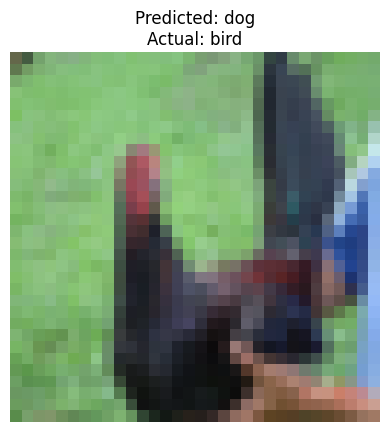

Confidence: 57.79%


In [37]:
import numpy as np
import matplotlib.pyplot as plt

class_names = [
    "airplane", "automobile", "bird", "cat", "deer",
    "dog", "frog", "horse", "ship", "truck"
]

index = 25

image = x_test[index]
prediction = resnet_model.predict(
    np.expand_dims(image, axis=0),
    verbose=0
)

predicted_class = np.argmax(prediction[0])

plt.imshow(image / 255.0)
plt.title(
    f"Predicted: {class_names[predicted_class]}\n"
    f"Actual: {class_names[int(y_test[index])]}"
)
plt.axis("off")
plt.show()

print(f"Confidence: {prediction[0][predicted_class] * 100:.2f}%")

In [38]:
resnet_model.save("cifar10_resnet_91.keras")

from google.colab import files
files.download("cifar10_resnet_91.keras")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

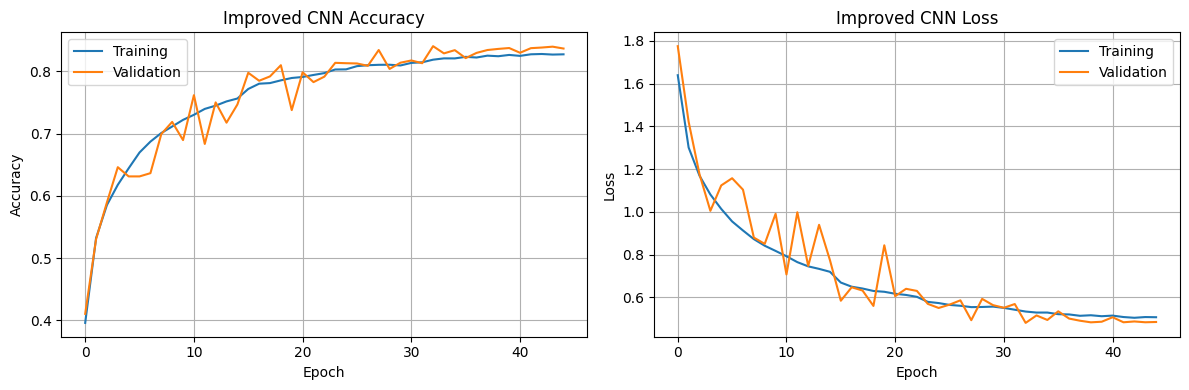

In [39]:

import matplotlib.pyplot as plt

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training")
plt.plot(history.history["val_accuracy"], label="Validation")
plt.title("Improved CNN Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training")
plt.plot(history.history["val_loss"], label="Validation")
plt.title("Improved CNN Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()


157/157 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step


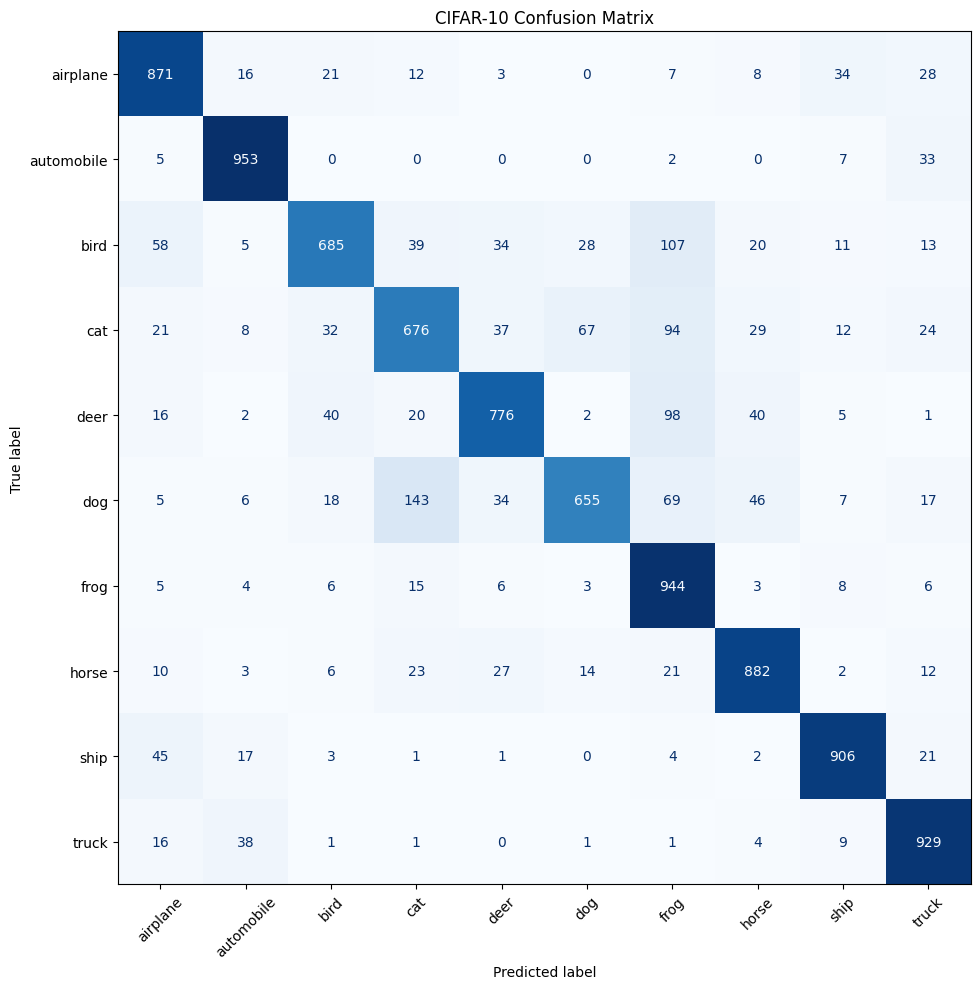

In [40]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

class_names = [
    "airplane", "automobile", "bird", "cat", "deer",
    "dog", "frog", "horse", "ship", "truck"
]

y_pred = np.argmax(model.predict(x_test, batch_size=64), axis=1)

cm = confusion_matrix(y_test.reshape(-1), y_pred)

fig, ax = plt.subplots(figsize=(10, 10))
ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
).plot(ax=ax, xticks_rotation=45, cmap="Blues", colorbar=False)

plt.title("CIFAR-10 Confusion Matrix")
plt.tight_layout()
plt.show()